In [83]:
import numpy as np 
import matplotlib.pyplot as plt 
from mlxtend.plotting import plot_decision_regions
from sklearn.datasets import make_moons
import seaborn as sns 

import tensorflow 
from tensorflow.keras.layers import Dense , Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.models import Sequential

In [84]:
import tensorflow as tf

print(tf.__version__)
print(tf.test.is_built_with_cuda())
print(tf.config.list_physical_devices('GPU'))

2.10.1
True
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [85]:
X, y = make_moons(100, noise= 0.25 , random_state = 42 )

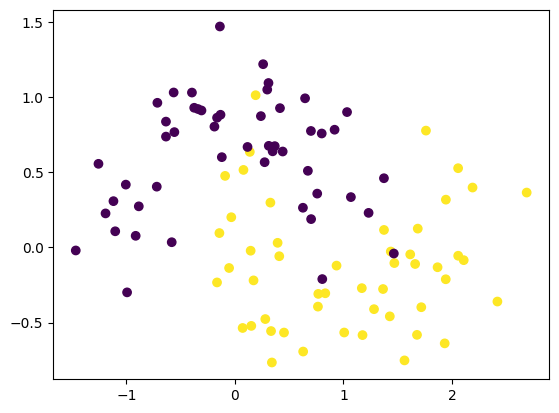

In [86]:
plt.scatter(X[: , 0], X[ : , 1 ], c=y)
plt.show()

In [87]:
model1 = Sequential()

model1.add(Dense(128, input_dim = 2 , activation = 'relu'))
model1.add(Dense(128, activation = 'relu'))
model1.add(Dense(1, activation = 'sigmoid'))

model1.summary()

Model: "sequential_9"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_12 (Dense)            (None, 128)               384       
                                                                 
 dense_13 (Dense)            (None, 128)               16512     
                                                                 
 dense_14 (Dense)            (None, 1)                 129       
                                                                 
Total params: 17,025
Trainable params: 17,025
Non-trainable params: 0
_________________________________________________________________


In [88]:
print(tf.config.list_physical_devices('GPU'))


[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [89]:
adam = Adam(learning_rate = 0.01)
model1.compile(loss = 'binary_crossentropy', optimizer = adam, metrics = ['accuracy'])

with tf.device('/GPU:0'):
    history1 = model1.fit(
        X,
        y,
        epochs= 2000 ,
        batch_size=256,
        validation_split=0.2,
        verbose = 1
    )

Epoch 1/2000
1/1 [==============================] - 1s 513ms/step - loss: 0.6924 - accuracy: 0.5000 - val_loss: 0.5610 - val_accuracy: 0.8000
Epoch 2/2000
1/1 [==============================] - 0s 29ms/step - loss: 0.5322 - accuracy: 0.8625 - val_loss: 0.4868 - val_accuracy: 0.8000
Epoch 3/2000
1/1 [==============================] - 0s 26ms/step - loss: 0.4304 - accuracy: 0.8625 - val_loss: 0.4453 - val_accuracy: 0.8000
Epoch 4/2000
1/1 [==============================] - 0s 29ms/step - loss: 0.3594 - accuracy: 0.8625 - val_loss: 0.4329 - val_accuracy: 0.8000
Epoch 5/2000
1/1 [==============================] - 0s 29ms/step - loss: 0.3171 - accuracy: 0.8625 - val_loss: 0.4402 - val_accuracy: 0.8000
Epoch 6/2000
1/1 [==============================] - 0s 30ms/step - loss: 0.3018 - accuracy: 0.8750 - val_loss: 0.4546 - val_accuracy: 0.8000
Epoch 7/2000
1/1 [==============================] - 0s 28ms/step - loss: 0.3042 - accuracy: 0.8875 - val_loss: 0.4680 - val_accuracy: 0.8000
Epoch 8/2000

9600/9600 [==============================] - 11s 1ms/step


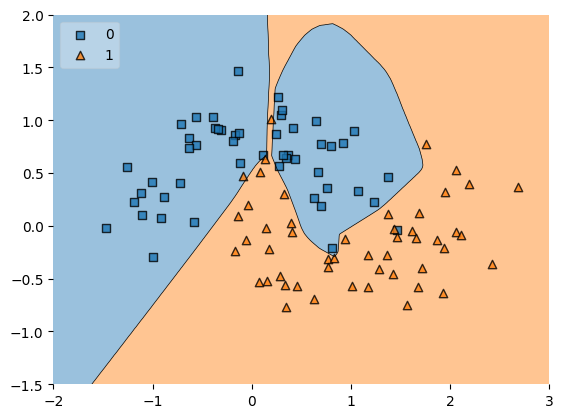

In [90]:
plot_decision_regions(X, y.astype('int'), clf = model1, legend = 2 )
plt.xlim(-2, 3 )
plt.ylim(-1.5 , 2)
plt.show()

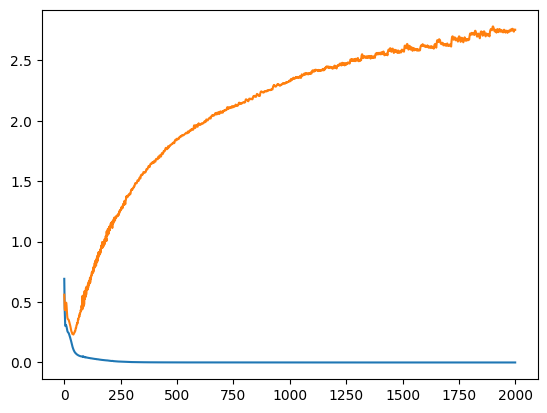

In [91]:
plt.plot(history1.history['loss'])
plt.plot(history1.history['val_loss'])


# **With L2 Regularization**

In [ ]:
model2 = Sequential()
# you can also use l1 regularization with tensorflow.keras.regularizers.l2(0.03)
model2.add(Dense(128, input_dim = 2 , activation = 'relu', kernel_regularizer =tensorflow.keras.regularizers.l2(0.03)))
model2.add(Dense(128, activation = 'relu', kernel_regularizer =tensorflow.keras.regularizers.l2(0.03) ))
model2.add(Dense(1, activation = 'sigmoid'))

model2.summary()

Model: "sequential_10"
_________________________________________________________________


 Layer (type)                Output Shape              Param #   
 dense_15 (Dense)            (None, 128)               384       
                                                                 
 dense_16 (Dense)            (None, 128)               16512     
                                                                 
 dense_17 (Dense)            (None, 1)                 129       
                                                                 
Total params: 17,025
Trainable params: 17,025
Non-trainable params: 0
_________________________________________________________________


In [93]:
adam = Adam(learning_rate = 0.01)
model2.compile(loss = 'binary_crossentropy', optimizer = adam, metrics = ['accuracy'])

with tf.device('/GPU:0'):
    history2 = model2.fit(
        X,
        y,
        epochs= 2000 ,
        batch_size=256,
        validation_split=0.2,
        verbose = 1
    )

Epoch 1/2000
1/1 [==============================] - 1s 552ms/step - loss: 4.6854 - accuracy: 0.4750 - val_loss: 3.9262 - val_accuracy: 0.8000
Epoch 2/2000
1/1 [==============================] - 0s 32ms/step - loss: 3.9174 - accuracy: 0.8125 - val_loss: 3.2793 - val_accuracy: 0.8000
Epoch 3/2000
1/1 [==============================] - 0s 32ms/step - loss: 3.2598 - accuracy: 0.8375 - val_loss: 2.7245 - val_accuracy: 0.8000
Epoch 4/2000
1/1 [==============================] - 0s 33ms/step - loss: 2.6957 - accuracy: 0.8375 - val_loss: 2.2565 - val_accuracy: 0.8000
Epoch 5/2000
1/1 [==============================] - 0s 31ms/step - loss: 2.2189 - accuracy: 0.8500 - val_loss: 1.8668 - val_accuracy: 0.8000
Epoch 6/2000
1/1 [==============================] - 0s 29ms/step - loss: 1.8199 - accuracy: 0.8500 - val_loss: 1.5478 - val_accuracy: 0.8000
Epoch 7/2000
1/1 [==============================] - 0s 30ms/step - loss: 1.4906 - accuracy: 0.8375 - val_loss: 1.2918 - val_accuracy: 0.8000
Epoch 8/2000

9600/9600 [==============================] - 9s 915us/step


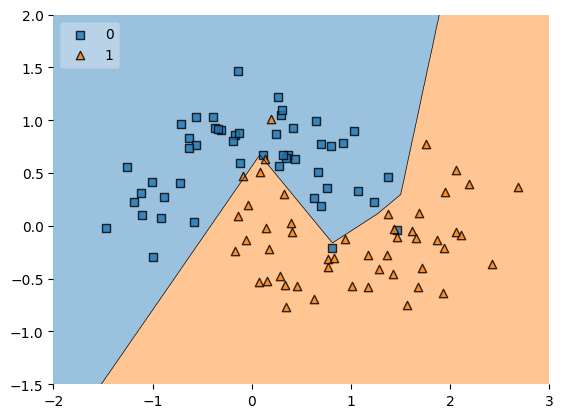

In [94]:
plot_decision_regions(X, y.astype('int'), clf = model2, legend = 2 )
plt.xlim(-2, 3 )
plt.ylim(-1.5 , 2)
plt.show()

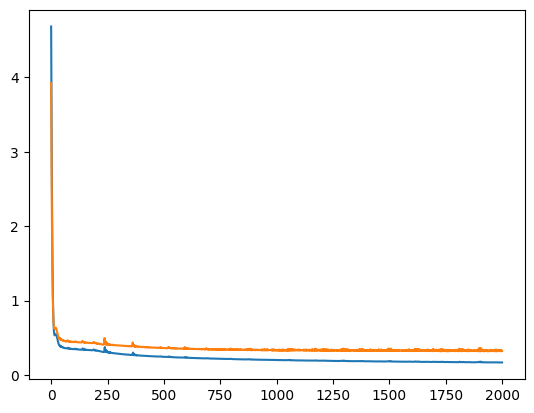

In [95]:
plt.plot(history2.history['loss'])
plt.plot(history2.history['val_loss'])

# See the weights of Model with Regularization
### The model which has regularization must have weights new/close to zero 

In [99]:
model1.get_weights()[0].reshape(256)

# MODEL_NAME.get_weights()[LAYER_NO.].reshape(MULTIPLY_THE_SHAPES)

array([ 2.39582196e-01,  1.49986193e-01, -3.96605879e-01, -4.06296462e-01,
        6.29426599e-01,  1.31235003e-01, -3.11660111e-01, -1.00603536e-01,
        6.42297745e-01, -7.16474891e-01,  4.29831088e-01,  5.38969934e-01,
       -2.47768134e-01,  2.48843789e-01,  4.78245050e-01,  1.52280614e-01,
       -4.69018489e-01, -4.72149029e-02,  4.34825867e-01, -4.69449669e-01,
       -4.18607205e-01, -5.88134266e-02, -2.87059218e-01,  5.06718516e-01,
        6.43170893e-01, -3.82992998e-03, -7.05382705e-01,  1.01422167e+00,
       -6.54682934e-01, -3.59020710e-01,  4.50378388e-01, -6.95228755e-01,
       -4.37362283e-01, -4.59827542e-01, -5.65166712e-01, -4.04653698e-01,
       -1.66981742e-01,  5.26476085e-01,  4.10848469e-01,  8.81600678e-01,
        1.08896732e+00, -3.33537310e-02, -1.11290272e-02,  2.16415942e-01,
       -4.72949505e-01, -5.14215171e-01, -5.58409035e-01, -3.82102013e-01,
       -5.76747417e-01, -4.20852005e-01, -5.31396009e-02,  2.24440277e-01,
        2.78947890e-01,  

In [126]:
model1_layer1_weights = model1.get_weights()[0].reshape(256)
model2_layer1_weights = model2.get_weights()[0].reshape(256)

<Axes: >

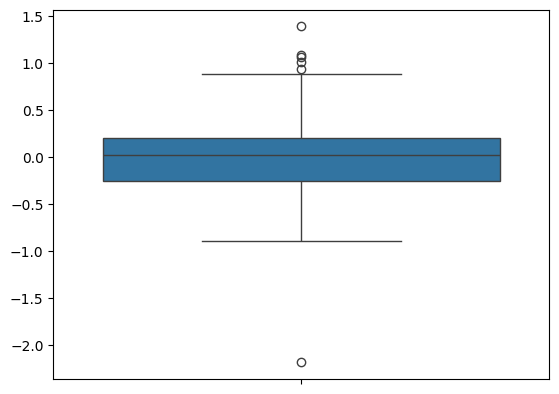

In [119]:
sns.boxplot(model1_layer1_weights)
# you can see here , the weights are spreaded from -1 to 1 

<Axes: >

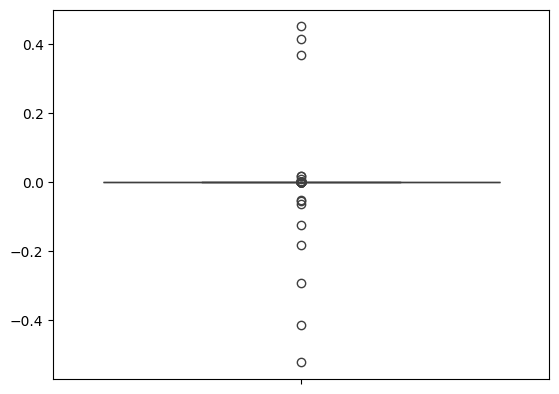

In [120]:
sns.boxplot(model2_layer1_weights)
# you can see here that regularised model has weights that are near to zero
# here wights are from -0.4 to 0.4 


In [121]:
model2_layer1_weights.min()

-0.522202

In [122]:
model1_layer1_weights.min()

-2.1792169

In [123]:
print(
    f"This is mininimum value of all weights from model1 : {model1_layer1_weights.min()}\n",
    f"This is mininimum value of all weights from model2 : {model2_layer1_weights.min()}\n",
    "**"*20,"\n",
    "**"*20,"\n",
    f"This is maximum value of all weights from model1 : {model1_layer1_weights.max()}\n",
    f"This is maximum value of all weights from model2 : {model2_layer1_weights.max()}\n",   

)

This is mininimum value of all weights from model1 : -2.1792168617248535
 This is mininimum value of all weights from model2 : -0.5222020149230957
 **************************************** 
 **************************************** 
 This is maximum value of all weights from model1 : 1.3890280723571777
 This is maximum value of all weights from model2 : 0.4508843719959259



<Axes: ylabel='Count'>

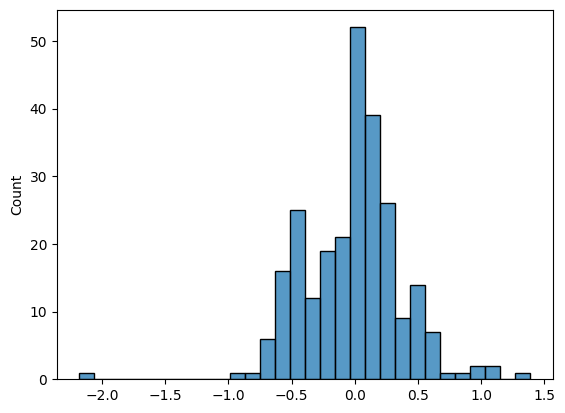

In [154]:
sns.histplot(model1_layer1_weights, bins = 30)

<Axes: ylabel='Count'>

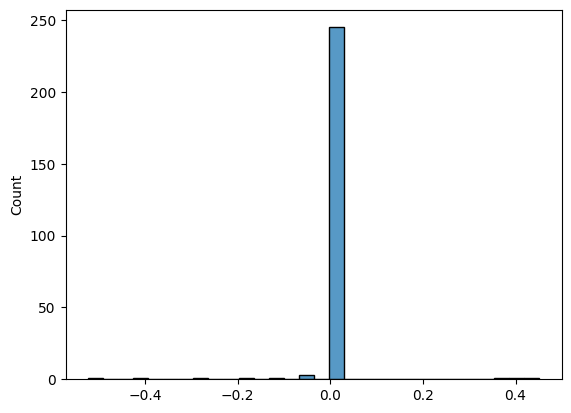

In [ ]:
sns.histplot(model2_layer1_weights, bins = 30 )

In [129]:
model2_layer1_weights.shape

(256,)

<Axes: ylabel='Density'>

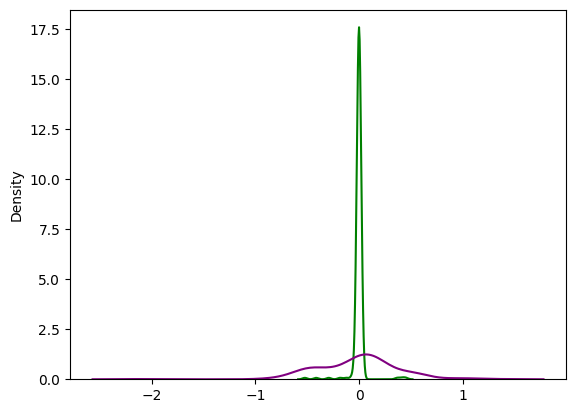

In [169]:
sns.kdeplot(model2_layer1_weights, color = 'green', label = 'model2')
sns.kdeplot(model1_layer1_weights, color = 'purple', label = 'model1')
